# Session 4: Inferential Statistics: Sampling, Hypotheses and Confidence

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    pass  # numpy, pandas, scipy, statsmodels and matplotlib are preinstalled in Colab
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/03-inferential-statistical-analysis/code/'
    for f in []:
        if not os.path.exists(f):
            subprocess.run(['wget', '-q', base + f], check=False)
print('ready')

ready


## Example: `session-04_sampling_methods.py`

In [2]:
"""
Session 4 · Example 1: Sampling methods compared
-----------------------------------------------
Population: 5,000 university students in three faculties with different
average monthly spending (thousand PKR). We draw samples of 100 with four
methods and compare their estimates of the true mean, repeating each method
2,000 times to see which is most PRECISE (smallest spread of estimates).

  * simple random sampling   - every student equally likely
  * systematic sampling      - every k-th student from a random start
  * stratified sampling      - proportional random samples from each faculty
  * cluster sampling         - pick whole tutorial groups (clusters) at random

Run:  python session-04_sampling_methods.py
"""
import numpy as np
import pandas as pd

rng = np.random.default_rng(5)
sizes = {"Engineering": 2000, "Business": 1800, "Arts": 1200}
means = {"Engineering": 28, "Business": 40, "Arts": 22}
pop = pd.concat([pd.DataFrame({"faculty": f, "spend": rng.normal(means[f], 6, n).round(1)})
                 for f, n in sizes.items()], ignore_index=True)
pop["group"] = np.arange(len(pop)) // 25                 # 200 tutorial groups of 25 students (sorted by faculty)
pop = pop.sample(frac=1, random_state=1).reset_index(drop=True)   # shuffle the register
mu = pop.spend.mean()
print(f"Population: N = {len(pop)}, true mean = {mu:.3f}, true sd = {pop.spend.std(ddof=0):.3f}")
print(pop.groupby("faculty").spend.agg(["count", "mean"]).round(2).to_string())

n = 100
def simple(): return pop.spend.sample(n, random_state=rng.integers(1e9)).mean()
def systematic():
    k = len(pop) // n
    start = rng.integers(k)
    return pop.spend.iloc[start::k].iloc[:n].mean()
def stratified():
    parts = [g.spend.sample(round(n * len(g) / len(pop)), random_state=rng.integers(1e9))
             for _, g in pop.groupby("faculty")]
    return pd.concat(parts).mean()
def cluster():
    chosen = rng.choice(pop.group.unique(), size=4, replace=False)   # 4 groups x 25 = 100 students
    return pop.spend[pop.group.isin(chosen)].mean()

print(f"\n{'method':<12} {'mean of estimates':>18} {'bias':>7} {'SE (sd of estimates)':>21}")
for name, fn in [("simple", simple), ("systematic", systematic), ("stratified", stratified), ("cluster", cluster)]:
    est = np.array([fn() for _ in range(2000)])
    print(f"{name:<12} {est.mean():>18.3f} {est.mean() - mu:>+7.3f} {est.std(ddof=1):>21.3f}")
print("\nAll four are unbiased; stratified is most precise (it removes between-faculty variation),")
print("cluster is least precise here because each tutorial group contains students of one faculty only.")

Population: N = 5000, true mean = 31.071, true sd = 9.408
             count   mean
faculty                  
Arts          1200  22.25
Business      1800  40.20
Engineering   2000  28.14

method        mean of estimates    bias  SE (sd of estimates)


simple                   31.046  -0.025                 0.924
systematic               31.079  +0.008                 0.881


stratified               31.067  -0.004                 0.603


cluster                  30.983  -0.087                 3.728

All four are unbiased; stratified is most precise (it removes between-faculty variation),
cluster is least precise here because each tutorial group contains students of one faculty only.


## Example: `session-04_confidence_intervals.py`

In [3]:
"""
Session 4 · Example 2: Standard error and confidence intervals
-------------------------------------------------------------
1. Build a 95% confidence interval for a mean, step by step (t interval).
2. A confidence interval for a proportion.
3. How sample size and confidence level change the width.
4. What '95% confidence' really means: draw 100 samples from a known
   population and count how many intervals capture the true mean.
   Chart saved to session-04_confidence_intervals.png

Run:  python session-04_confidence_intervals.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---- 1. CI for a mean: daily mobile-data use (GB) of 12 students -----------------
x = np.array([1.8, 2.4, 3.1, 2.2, 2.9, 1.5, 3.6, 2.7, 2.0, 3.3, 2.5, 2.8])
n, xbar, s = len(x), x.mean(), x.std(ddof=1)
se = s / np.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n - 1)
print("1) 95% CI for mean data use")
print(f"   n = {n}, x_bar = {xbar:.3f}, s = {s:.3f}, SE = s/sqrt(n) = {se:.4f}")
print(f"   t* (df = {n - 1}) = {t_crit:.3f}, margin of error = {t_crit * se:.3f}")
print(f"   CI = [{xbar - t_crit * se:.3f}, {xbar + t_crit * se:.3f}] GB")
print("   scipy:", tuple(round(float(v), 3) for v in stats.t.interval(0.95, n - 1, loc=xbar, scale=se)))

# ---- 2. CI for a proportion: 312 of 520 surveyed customers prefer digital payment -
k, m = 312, 520
p_hat = k / m
se_p = np.sqrt(p_hat * (1 - p_hat) / m)
z = stats.norm.ppf(0.975)
print(f"\n2) Proportion: p_hat = {p_hat:.3f}, SE = {se_p:.4f}, "
      f"95% CI = [{p_hat - z * se_p:.3f}, {p_hat + z * se_p:.3f}]")
# Sample size needed for a +/- 3 percentage-point margin (worst case p = 0.5)
print(f"   Sample size for a +/-3% margin: n = {int(np.ceil((z / 0.03) ** 2 * 0.25))}")

# ---- 3. Width vs n and confidence level -----------------------------------------
print("\n3) Width of a CI for a mean with s = 10")
print("   n      90%     95%     99%")
for nn in [10, 40, 160, 640]:
    w = [2 * stats.t.ppf(1 - a / 2, nn - 1) * 10 / np.sqrt(nn) for a in (0.10, 0.05, 0.01)]
    print(f"   {nn:<5}" + "".join(f"{v:8.2f}" for v in w))
print("   4x the sample -> about half the width; more confidence -> wider interval")

# ---- 4. Coverage simulation --------------------------------------------------------
rng = np.random.default_rng(8)
mu, sigma, nn = 50, 12, 25
hits, rows = 0, []
for i in range(100):
    smp = rng.normal(mu, sigma, nn)
    lo, hi = stats.t.interval(0.95, nn - 1, loc=smp.mean(), scale=smp.std(ddof=1) / np.sqrt(nn))
    ok = lo <= mu <= hi
    hits += ok
    rows.append((lo, hi, ok))
print(f"\n4) {hits} of 100 intervals contain the true mean {mu} (expected about 95)")

fig, ax = plt.subplots(figsize=(10, 4))
for i, (lo, hi, ok) in enumerate(rows):
    ax.plot([i, i], [lo, hi], color="#A78BFA" if ok else "#F43F5E", lw=2 if not ok else 1.2)
ax.axhline(mu, color="#FF6B1A", lw=2, label="true mean = 50")
ax.set_xlabel("sample number"); ax.set_ylabel("95% CI")
ax.set_title(f"100 confidence intervals: {hits} capture the true mean (red = miss)")
ax.legend(); fig.tight_layout(); fig.savefig("session-04_confidence_intervals.png", dpi=100)
print("Saved chart: session-04_confidence_intervals.png")

1) 95% CI for mean data use
   n = 12, x_bar = 2.567, s = 0.624, SE = s/sqrt(n) = 0.1802
   t* (df = 11) = 2.201, margin of error = 0.397
   CI = [2.170, 2.963] GB
   scipy: (2.17, 2.963)

2) Proportion: p_hat = 0.600, SE = 0.0215, 95% CI = [0.558, 0.642]
   Sample size for a +/-3% margin: n = 1068

3) Width of a CI for a mean with s = 10
   n      90%     95%     99%
   10      11.59   14.31   20.55
   40       5.33    6.40    8.56
   160      2.62    3.12    4.12
   640      1.30    1.55    2.04
   4x the sample -> about half the width; more confidence -> wider interval

4) 94 of 100 intervals contain the true mean 50 (expected about 95)
Saved chart: session-04_confidence_intervals.png


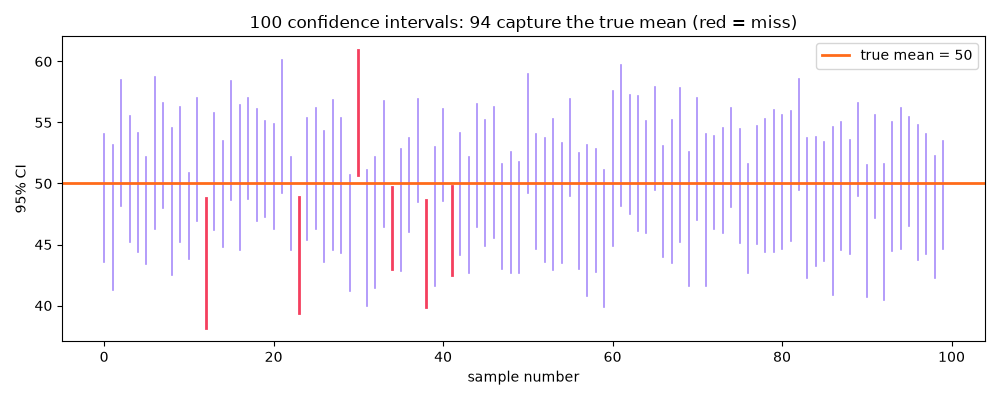

In [4]:
from IPython.display import Image, display
display(Image(filename='session-04_confidence_intervals.png'))  # chart saved by the cell above

## Example: `session-04_hypothesis_test.py`

In [5]:
"""
Session 4 · Example 3: The hypothesis-testing procedure, step by step
--------------------------------------------------------------------
A juice factory claims each bottle holds 500 ml. An inspector measures 15
bottles. Is the true mean different from 500 ml?  (two-tailed one-sample t test)

Then we SIMULATE:
  * Type I error rate  - how often we wrongly reject a TRUE H0 at alpha = 0.05
  * Power              - how often we correctly reject a FALSE H0, for several n

Run:  python session-04_hypothesis_test.py
"""
import numpy as np
from scipy import stats

ml = np.array([497.2, 499.1, 495.8, 498.4, 500.3, 496.9, 497.7, 499.6,
               494.9, 498.1, 497.4, 501.0, 496.2, 498.8, 497.5])
mu0, alpha = 500, 0.05

print("Step 1. Hypotheses:  H0: mu = 500 ml    H1: mu != 500 ml   (two-tailed)")
print(f"Step 2. Significance level alpha = {alpha}")
n, xbar, s = len(ml), ml.mean(), ml.std(ddof=1)
se = s / np.sqrt(n)
t = (xbar - mu0) / se
print(f"Step 3. Test statistic: t = (x_bar - mu0) / (s / sqrt(n)) = ({xbar:.3f} - {mu0}) / {se:.4f} = {t:.3f}")
crit = stats.t.ppf(1 - alpha / 2, n - 1)
p = 2 * stats.t.sf(abs(t), n - 1)
print(f"Step 4. Critical values +/-{crit:.3f} (df = {n - 1});  p-value = {p:.5f}")
decision = "REJECT H0" if p < alpha else "FAIL TO REJECT H0"
print(f"Step 5. Decision: |t| = {abs(t):.2f} {'>' if abs(t) > crit else '<='} {crit:.2f} and p "
      f"{'<' if p < alpha else '>='} {alpha} -> {decision}")
print("Step 6. Conclusion: the bottles hold less than the labelled 500 ml on average." if p < alpha
      else "Step 6. Conclusion: no evidence the mean differs from 500 ml.")
res = stats.ttest_1samp(ml, mu0)
print(f"Check with scipy: t = {res.statistic:.3f}, p = {res.pvalue:.5f}")
lo, hi = stats.t.interval(0.95, n - 1, loc=xbar, scale=se)
print(f"95% CI [{lo:.2f}, {hi:.2f}] does not contain 500 -> same decision as the test" if not lo <= 500 <= hi
      else f"95% CI [{lo:.2f}, {hi:.2f}] contains 500")

# One-tailed version: consumer group suspects UNDER-filling (H1: mu < 500)
p_one = stats.t.cdf(t, n - 1)
print(f"\nOne-tailed (H1: mu < 500): p = {p_one:.5f}  (half the two-tailed p because t is negative)")

# ---- Simulating Type I error and power -------------------------------------------
rng = np.random.default_rng(1)
reps = 5000
true_h0 = rng.normal(500, 2, size=(reps, 15))
p_vals = stats.ttest_1samp(true_h0, 500, axis=1).pvalue
print(f"\nType I error rate when H0 is true: {np.mean(p_vals < alpha):.3f}  (should be about {alpha})")
print("Power to detect a real mean of 499 ml (sd 2):")
for nn in [10, 25, 50, 100]:
    smp = rng.normal(499, 2, size=(reps, nn))
    power = np.mean(stats.ttest_1samp(smp, 500, axis=1).pvalue < alpha)
    print(f"   n = {nn:>3}: power = {power:.3f}   P(Type II error) = {1 - power:.3f}")

Step 1. Hypotheses:  H0: mu = 500 ml    H1: mu != 500 ml   (two-tailed)
Step 2. Significance level alpha = 0.05
Step 3. Test statistic: t = (x_bar - mu0) / (s / sqrt(n)) = (497.927 - 500) / 0.4311 = -4.809
Step 4. Critical values +/-2.145 (df = 14);  p-value = 0.00028
Step 5. Decision: |t| = 4.81 > 2.14 and p < 0.05 -> REJECT H0
Step 6. Conclusion: the bottles hold less than the labelled 500 ml on average.
Check with scipy: t = -4.809, p = 0.00028
95% CI [497.00, 498.85] does not contain 500 -> same decision as the test

One-tailed (H1: mu < 500): p = 0.00014  (half the two-tailed p because t is negative)

Type I error rate when H0 is true: 0.043  (should be about 0.05)
Power to detect a real mean of 499 ml (sd 2):
   n =  10: power = 0.293   P(Type II error) = 0.707
   n =  25: power = 0.675   P(Type II error) = 0.325
   n =  50: power = 0.930   P(Type II error) = 0.070


   n = 100: power = 0.998   P(Type II error) = 0.002


## Example: `session-04_problem_battery_claim.py`

In [6]:
"""
Session 4 · Real-life problem: testing a power-bank seller's claim
-----------------------------------------------------------------
PROBLEM
An online seller claims its 10,000 mAh power bank gives AT LEAST 20 hours of
phone use on average, and that NO MORE than 5% of units are faulty.
A university tech club tests 40 units:
  * hours of use (data below)
  * 5 of the 40 units were faulty
At alpha = 0.05:
  1. Is there evidence that mean battery life is LESS than 20 hours? (one-tailed t)
  2. Is there evidence that the fault rate is MORE than 5%?        (one-tailed z for a proportion,
     plus an exact binomial test because n*p0 = 2 is small)
  3. Give 95% confidence intervals for both.
  4. Write a short, non-technical verdict.

Run:  python session-04_problem_battery_claim.py
"""
import numpy as np
from scipy import stats

hours = np.array([19.2, 20.5, 18.7, 19.9, 21.1, 18.4, 19.6, 20.2, 18.9, 19.4,
                  20.8, 19.1, 18.6, 19.8, 20.1, 19.3, 18.8, 21.0, 19.5, 19.0,
                  20.4, 18.5, 19.7, 20.0, 19.2, 18.9, 20.6, 19.4, 19.1, 20.3,
                  18.7, 19.9, 19.6, 20.9, 18.8, 19.3, 20.2, 19.0, 19.5, 18.6])
alpha = 0.05

# ---- 1. Mean battery life -----------------------------------------------------------
n, xbar, s = len(hours), hours.mean(), hours.std(ddof=1)
t = (xbar - 20) / (s / np.sqrt(n))
p1 = stats.t.cdf(t, n - 1)                       # lower-tailed
print("1) H0: mu >= 20 h   vs   H1: mu < 20 h")
print(f"   n = {n}, mean = {xbar:.3f} h, sd = {s:.3f}, t = {t:.3f}, p = {p1:.5f}")
print("   ->", "reject H0: mean life is below 20 h" if p1 < alpha else "not enough evidence")
res = stats.ttest_1samp(hours, 20, alternative="less")
print(f"   scipy check: t = {res.statistic:.3f}, p = {res.pvalue:.5f}")

# ---- 2. Fault rate ---------------------------------------------------------------------
k, p0 = 5, 0.05
p_hat = k / n
z = (p_hat - p0) / np.sqrt(p0 * (1 - p0) / n)    # SE uses p0 under H0
p_z = stats.norm.sf(z)
p_exact = stats.binomtest(k, n, p0, alternative="greater").pvalue
print("\n2) H0: p <= 0.05   vs   H1: p > 0.05")
print(f"   p_hat = {p_hat:.3f}, z = {z:.3f}, normal-approx p = {p_z:.4f}")
print(f"   n*p0 = {n * p0:.0f} < 10, so the normal approximation is shaky; exact binomial p = {p_exact:.4f}")
print("   ->", "reject H0" if p_exact < alpha else "fail to reject H0: 5/40 is suspicious but not conclusive")

# ---- 3. Confidence intervals ----------------------------------------------------------
lo, hi = stats.t.interval(0.95, n - 1, loc=xbar, scale=s / np.sqrt(n))
ci_p = stats.binomtest(k, n).proportion_ci(confidence_level=0.95, method="wilson")
print(f"\n3) 95% CI mean life: [{lo:.2f}, {hi:.2f}] h")
print(f"   95% CI fault rate (Wilson): [{ci_p.low:.3f}, {ci_p.high:.3f}]")

# ---- 4. Verdict -------------------------------------------------------------------------
print(f"\n4) Verdict: average life is about {xbar:.1f} h, significantly below the advertised 20 h. "
      f"The fault rate in our sample ({p_hat:.1%}) is also significantly above 5% "
      f"(exact p = {p_exact:.3f}), but only just, and the plausible range is wide "
      f"({ci_p.low:.0%} to {ci_p.high:.0%}); test more units before a formal complaint about faults.")

1) H0: mu >= 20 h   vs   H1: mu < 20 h
   n = 40, mean = 19.562 h, sd = 0.750, t = -3.690, p = 0.00034
   -> reject H0: mean life is below 20 h
   scipy check: t = -3.690, p = 0.00034

2) H0: p <= 0.05   vs   H1: p > 0.05
   p_hat = 0.125, z = 2.176, normal-approx p = 0.0148
   n*p0 = 2 < 10, so the normal approximation is shaky; exact binomial p = 0.0480
   -> reject H0

3) 95% CI mean life: [19.32, 19.80] h
   95% CI fault rate (Wilson): [0.055, 0.261]

4) Verdict: average life is about 19.6 h, significantly below the advertised 20 h. The fault rate in our sample (12.5%) is also significantly above 5% (exact p = 0.048), but only just, and the plausible range is wide (5% to 26%); test more units before a formal complaint about faults.


## Example: `session-04_project_ab_test.py`

In [7]:
"""
Session 4 · Mini project: an A/B testing toolkit for a website
-------------------------------------------------------------
An online bookshop tests a new 'Buy now' button (B) against the old one (A).
The toolkit:
  1. plans the experiment: sample size per group for a chosen minimum effect,
     alpha and power (normal-approximation formula)
  2. analyses the results: two-proportion z test, p-value, 95% CI for the lift
  3. double-checks with a permutation test (no formulas, just shuffling)
  4. shows the danger of 'peeking' (stopping as soon as p < 0.05) by simulation
  5. saves a chart of the conversion rates with CIs: session-04_project_ab_test.png

Run:  python session-04_project_ab_test.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

def sample_size(p1, p2, alpha=0.05, power=0.80):
    """Visitors needed PER GROUP to detect p1 -> p2 with a two-sided test."""
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    pbar = (p1 + p2) / 2
    num = (za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return int(np.ceil(num / (p1 - p2) ** 2))

def two_prop_test(xa, na, xb, nb):
    pa, pb = xa / na, xb / nb
    pool = (xa + xb) / (na + nb)
    se0 = np.sqrt(pool * (1 - pool) * (1 / na + 1 / nb))          # SE under H0 (pooled)
    z = (pb - pa) / se0
    p = 2 * stats.norm.sf(abs(z))
    se = np.sqrt(pa * (1 - pa) / na + pb * (1 - pb) / nb)           # SE for the CI (unpooled)
    diff = pb - pa
    return pa, pb, z, p, (diff - 1.96 * se, diff + 1.96 * se)

# 1. Plan
n_needed = sample_size(0.040, 0.050)
print(f"1) To detect 4.0% -> 5.0% with alpha 0.05 and power 0.80: {n_needed:,} visitors per group")

# 2. Analyse (results after running the test with that many visitors)
na = nb = 6800
xa, xb = 272, 343
pa, pb, z, p, ci = two_prop_test(xa, na, xb, nb)
print(f"\n2) A: {xa}/{na} = {pa:.2%}   B: {xb}/{nb} = {pb:.2%}")
print(f"   z = {z:.3f}, p = {p:.4f}, lift = {pb - pa:+.2%} (95% CI {ci[0]:+.2%} to {ci[1]:+.2%}), "
      f"relative lift = {(pb / pa - 1):+.1%}")
print("   ->", "B is significantly better: ship it" if p < 0.05 and ci[0] > 0 else "no clear winner")

# 3. Permutation test
rng = np.random.default_rng(0)
outcomes = np.r_[np.ones(xa + xb), np.zeros(na + nb - xa - xb)]
observed = pb - pa
diffs = np.empty(2000)
for i in range(2000):
    rng.shuffle(outcomes)
    diffs[i] = outcomes[:nb].mean() - outcomes[nb:].mean()
print(f"\n3) Permutation test: p = {np.mean(np.abs(diffs) >= abs(observed)):.4f} (2,000 shuffles)")

# 4. The peeking problem: A and B are IDENTICAL (4% each), but we check after every 500 visitors
false_wins = 0
for _ in range(1000):
    a = rng.random(10_000) < 0.04
    b = rng.random(10_000) < 0.04
    for m in range(500, 10_001, 500):
        if two_prop_test(a[:m].sum(), m, b[:m].sum(), m)[3] < 0.05:
            false_wins += 1
            break
print(f"\n4) Peeking 20 times when there is NO real difference: false 'winner' in {false_wins / 10:.1f}% "
      f"of experiments (should be 5%)")

# 5. Chart
fig, ax = plt.subplots(figsize=(6, 4))
rates = [pa, pb]
errs = [1.96 * np.sqrt(r * (1 - r) / n) for r, n in zip(rates, [na, nb])]
ax.bar(["A (old button)", "B (new button)"], [100 * r for r in rates], yerr=[100 * e for e in errs],
       color=["#A78BFA", "#FF6B1A"], capsize=8)
ax.set_ylabel("conversion rate (%)"); ax.set_title(f"A/B test: p = {p:.4f}")
for i, r in enumerate(rates):
    ax.text(i, 100 * r / 2, f"{r:.2%}", ha="center", color="white", fontweight="bold")
fig.tight_layout(); fig.savefig("session-04_project_ab_test.png", dpi=100)
print("Saved chart: session-04_project_ab_test.png")

1) To detect 4.0% -> 5.0% with alpha 0.05 and power 0.80: 6,745 visitors per group

2) A: 272/6800 = 4.00%   B: 343/6800 = 5.04%
   z = 2.930, p = 0.0034, lift = +1.04% (95% CI +0.35% to +1.74%), relative lift = +26.1%
   -> B is significantly better: ship it



3) Permutation test: p = 0.0025 (2,000 shuffles)



4) Peeking 20 times when there is NO real difference: false 'winner' in 26.8% of experiments (should be 5%)
Saved chart: session-04_project_ab_test.png


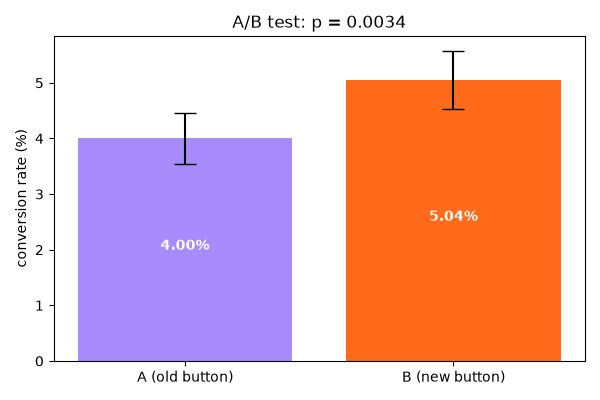

In [8]:
from IPython.display import Image, display
display(Image(filename='session-04_project_ab_test.png'))  # chart saved by the cell above